# Charts and Diagrams

Cells run in a Web Worker, which has no DOM, so the charts here are drawn
as SVG in the kernel. `jupyter.chart` does that for Vega-Lite and
Observable Plot; d3's scales and shapes and Graphviz compiled to
WebAssembly build SVG text that `jupyter.svg` shows.

## Data

Four years of Seattle weather from the
[vega-datasets](https://github.com/vega/vega-datasets) collection, parsed
with d3's CSV reader.

In [1]:
import { csvParse, autoType } from "npm:d3-dsv@3";
const csv = await (await fetch("https://raw.githubusercontent.com/vega/vega-datasets/v2.11.0/data/seattle-weather.csv")).text();
type Day = { date: Date; precipitation: number; temp_max: number; temp_min: number; wind: number; weather: string };
const days = csvParse(csv, autoType) as unknown as Day[];
`${days.length} days, ${days[0].date.toISOString().slice(0, 10)} to ${days.at(-1)!.date.toISOString().slice(0, 10)}`;

'1461 days, 2012-01-01 to 2015-12-31'

## A line chart with d3

d3's scales map values to pixels and its shapes build SVG paths. Here,
each month's average high and low for 2015.

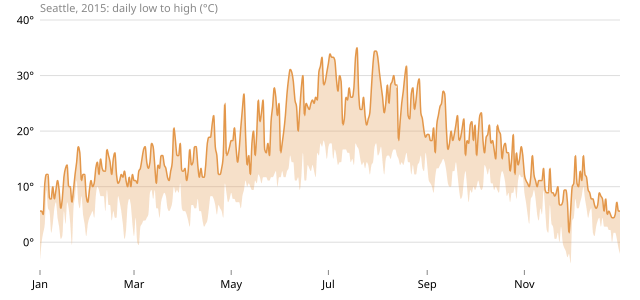

In [2]:
import { scaleLinear, scaleUtc } from "npm:d3-scale@4";
import { line, area, curveMonotoneX } from "npm:d3-shape@3";
import { utcMonth } from "npm:d3-time@3";
import { utcFormat } from "npm:d3-time-format@4";

const year = days.filter(d => d.date.getUTCFullYear() === 2015);
const W = 640, H = 300, M = { top: 20, right: 20, bottom: 30, left: 40 };
const x = scaleUtc().domain([year[0].date, year.at(-1)!.date]).range([M.left, W - M.right]);
const y = scaleLinear().domain([-5, 40]).range([H - M.bottom, M.top]);

const band = area<Day>().x(d => x(d.date)).y0(d => y(d.temp_min)).y1(d => y(d.temp_max)).curve(curveMonotoneX)(year)!;
const highs = line<Day>().x(d => x(d.date)).y(d => y(d.temp_max)).curve(curveMonotoneX)(year)!;
const xTicks = x.ticks(utcMonth.every(2)!).map(t =>
  `<g transform="translate(${x(t)},${H - M.bottom})"><line y2="5" stroke="currentColor"/><text y="18" text-anchor="middle">${utcFormat("%b")(t)}</text></g>`);
const yTicks = y.ticks(5).map(t =>
  `<g transform="translate(${M.left},${y(t)})"><line x2="${W - M.left - M.right}" stroke="#8884"/><text x="-6" dy="4" text-anchor="end">${t}°</text></g>`);

jupyter.svg`<svg xmlns="http://www.w3.org/2000/svg" width="${W}" height="${H}" font-family="system-ui" font-size="11" style="color:#888">
  ${yTicks.join("")}${xTicks.join("")}
  <path d="${band}" fill="#e3974a" fill-opacity="0.3"/>
  <path d="${highs}" fill="none" stroke="#e3974a" stroke-width="1.5"/>
  <text x="${M.left}" y="12" fill="currentColor">Seattle, 2015: daily low to high (°C)</text>
</svg>`;

## Vega-Lite

[Vega-Lite](https://vega.github.io/vega-lite/) describes a chart as JSON:
data, a mark, and encodings. `jupyter.chart` renders it to one SVG, title
and legend included, and loads Vega the first time a cell draws a chart.

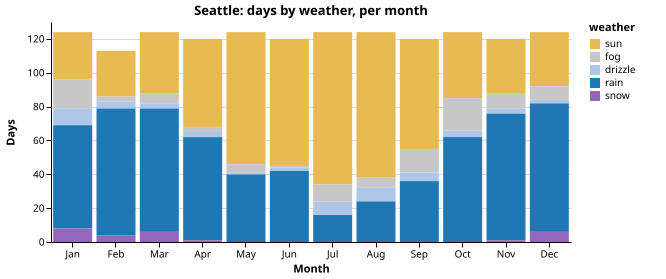

In [3]:
jupyter.chart({
  title: "Seattle: days by weather, per month",
  width: 520,
  height: 220,
  data: { values: days },
  mark: "bar",
  encoding: {
    x: { timeUnit: "month", field: "date", type: "ordinal", title: "Month" },
    y: { aggregate: "count", type: "quantitative", title: "Days" },
    color: {
      field: "weather",
      type: "nominal",
      scale: { domain: ["sun", "fog", "drizzle", "rain", "snow"], range: ["#e7ba52", "#c7c7c7", "#aec7e8", "#1f77b4", "#9467bd"] },
    },
  },
});

Any Vega-Lite spec works. A scatter plot of wind against rain, one point
per rainy day of 2015:

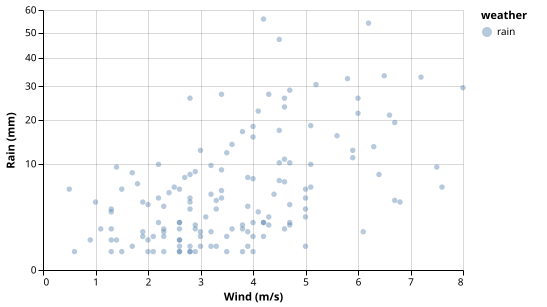

In [4]:
jupyter.chart({
  width: 420,
  height: 260,
  data: { values: year.filter(d => d.precipitation > 0) },
  mark: { type: "point", filled: true, opacity: 0.4 },
  encoding: {
    x: { field: "wind", type: "quantitative", title: "Wind (m/s)" },
    y: { field: "precipitation", type: "quantitative", scale: { type: "sqrt" }, title: "Rain (mm)" },
    color: { field: "weather", type: "nominal" },
  },
});

## Observable Plot

[Observable Plot](https://observablehq.com/plot/) builds a chart from
marks in code. Pass `jupyter.chart` the Plot module and the options you
would give `Plot.plot`; it supplies the DOM Plot needs and draws the title
and color legend into the SVG. Four years of daily highs, as a box per
month:

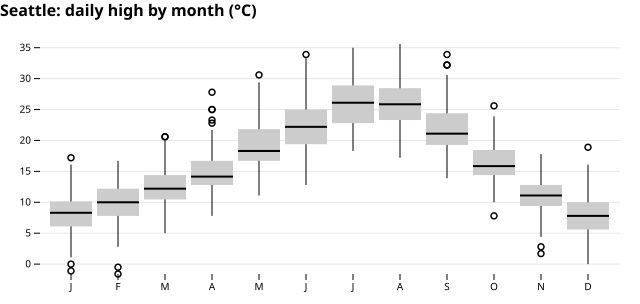

In [5]:
import * as Plot from "npm:@observablehq/plot@0.6.17";

jupyter.chart(Plot, {
  title: "Seattle: daily high by month (°C)",
  width: 640,
  height: 280,
  x: { tickFormat: (m: number) => "JFMAMJJASOND"[m] },
  y: { grid: true, label: null },
  marks: [Plot.boxY(days, { x: d => d.date.getUTCMonth(), y: "temp_max" })],
});

## Diagrams with Graphviz

[Graphviz](https://graphviz.org) lays out graphs written in its DOT
language. `@hpcc-js/wasm-graphviz` is Graphviz compiled to WebAssembly.

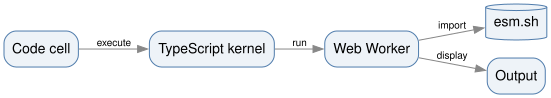

In [6]:
import { Graphviz } from "npm:@hpcc-js/wasm-graphviz@1";
const graphviz = await Graphviz.load();
const dot = (source: string) => jupyter.svg`${graphviz.dot(source)}`;

dot(`digraph {
  rankdir=LR; bgcolor="transparent";
  node [shape=box, style="rounded,filled", fillcolor="#eef3f8", color="#4f7cac", fontname="Helvetica"];
  edge [color="#888888", fontname="Helvetica", fontsize=10];
  cell [label="Code cell"]; kernel [label="TypeScript kernel"]; worker [label="Web Worker"];
  cdn [label="esm.sh", shape=cylinder]; output [label="Output"];
  cell -> kernel [label="execute"]; kernel -> worker [label="run"];
  worker -> cdn [label="import"]; worker -> output [label="display"];
}`);

DOT is text, so a diagram can come from data. Each moon's orbit, from the
closest:

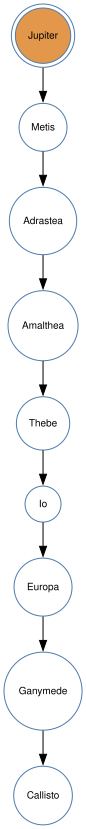

In [7]:
const moons = ["Metis", "Adrastea", "Amalthea", "Thebe", "Io", "Europa", "Ganymede", "Callisto"];
dot(`digraph {
  bgcolor="transparent"; node [shape=circle, fontname="Helvetica", fontsize=10, color="#4f7cac"];
  Jupiter [shape=doublecircle, style=filled, fillcolor="#e3974a"];
  ${moons.map((m, i) => `${i === 0 ? "Jupiter" : moons[i - 1]} -> ${m};`).join(" ")}
}`);